Training data: (40000, 3072)
Testing data: (10000, 3072)


C:\Users\SAKSHI\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 27ms/step - accuracy: 0.3189 - loss: 1.8884 - val_accuracy: 0.3780 - val_loss: 1.7359
Epoch 2/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 59s 47ms/step - accuracy: 0.3850 - loss: 1.7037 - val_accuracy: 0.3886 - val_loss: 1.7036
Epoch 3/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 24ms/step - accuracy: 0.4149 - loss: 1.6276 - val_accuracy: 0.4265 - val_loss: 1.6187
Epoch 4/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 85s 68ms/step - accuracy: 0.4358 - loss: 1.5690 - val_accuracy: 0.4440 - val_loss: 1.5614
Epoch 5/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 86s 24ms/step - accuracy: 0.4500 - loss: 1.5357 - val_accuracy: 0.4511 - val_loss: 1.5615
Epoch 6/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 34s 27ms/step - accuracy: 0.4597 - loss: 1.5052 - val_accuracy: 0.4378 - val_loss: 1.5667
Epoch 7/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 44s 35ms/step - accuracy: 0.4678 - loss: 1.4791 - val_accuracy: 0.4642 - val_loss: 1.5179
Epoch 8/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 24ms/step - accuracy: 0.4807 -

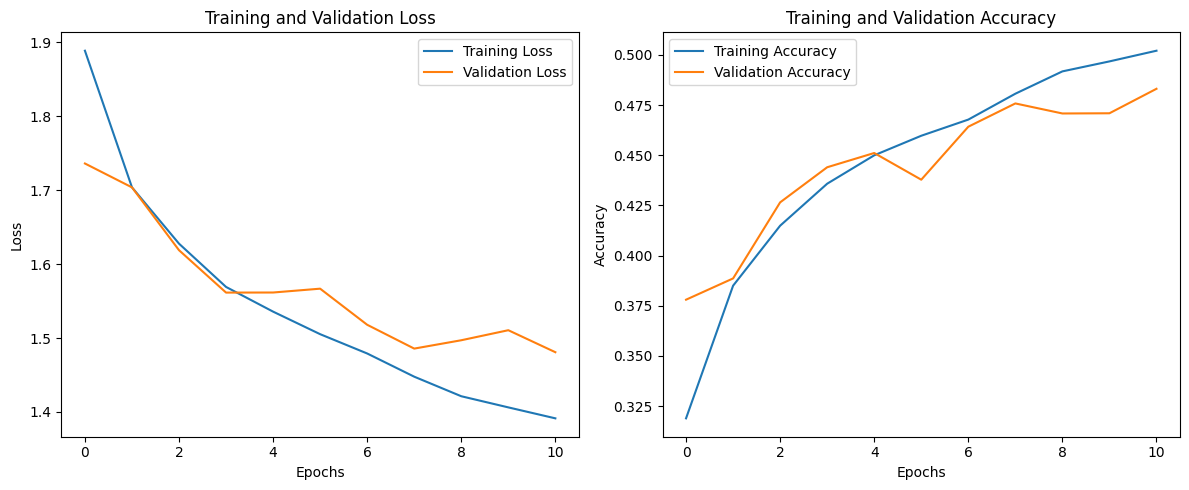

In [3]:

# LP-IV: Feedforward Neural Network using CIFAR-10 Dataset

# a. Import necessary packages
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# b. Load training data
data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\FNN and CNN\CIFAR10\cifar-10.csv')

# Separate input features and output labels
X = data.drop('label', axis=1).values
y = data['label'].values

# Split into training and testing data (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Class names
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat',
               'Deer', 'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

# c. Define Feedforward Neural Network
model = Sequential([
    Dense(512, activation='relu', input_shape=(3072,)),
    Dense(256, activation='relu'),
    Dense(10, activation='softmax')
])

# d. Compile and train using Adam optimizer
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    epochs=11,
    validation_data=(X_test, y_test)
)

# e. Evaluate the network
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# f. Plot training loss and accuracy
plt.figure(figsize=(12, 5))

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy graph
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


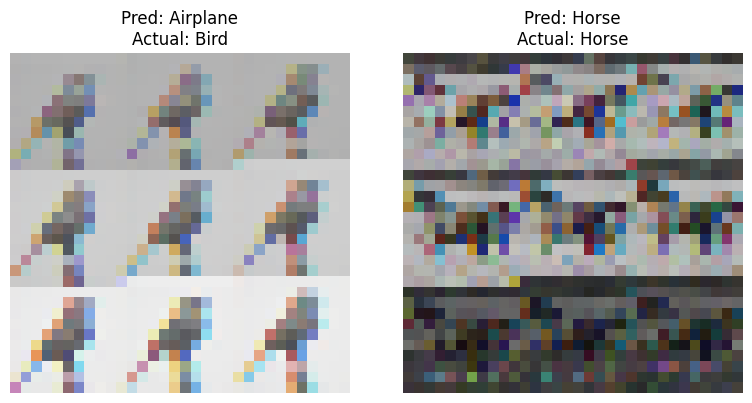

In [4]:
# Display 2 sample predictions
predictions = model.predict(X_test)
predicted_labels = predictions.argmax(axis=1)

plt.figure(figsize=(8, 4))

for i in range(2):
    plt.subplot(1, 2, i+1)

    # Convert flattened pixels into an RGB image
    image = X_test[i].reshape(32, 32, 3)

    plt.imshow(image)

    plt.title("Pred: " + class_names[predicted_labels[i]] +
              "\nActual: " + class_names[y_test[i]])

    plt.axis('off')

plt.tight_layout()
plt.show()